# Weather Prediction Near Irvine

AI SCI 290A - My progress notebook

My question: can I predict tomorrow's daily mean temperature near Irvine using today's temperature and recent days? I am working through the data and trying simple models one step at a time.

## 1. Load the temperature data

I use the 2009-2010 NetCDF files. `t2m` means temperature at 2 meters above the surface.

In [1]:
# Import the tools for finding files and reading the data.
import glob
import xarray as xr


In [2]:
# Find the temperature files and open them together.
DATA_DIR = r"C:\Users\giorg\Desktop\290A\Project1_WeatherPrediction\data\data"

temp_files = sorted(
    glob.glob(f"{DATA_DIR}/**/2m_temperature*.nc", recursive=True)
)

ds_temp = xr.open_mfdataset(temp_files, combine="by_coords")
T2M = ds_temp["t2m"]

T2M


<xarray.DataArray 't2m' (valid_time: 730, latitude: 105, longitude: 237)> Size: 73MB
dask.array<concatenate, shape=(730, 105, 237), dtype=float32, chunksize=(62, 105, 237), chunktype=numpy.ndarray>
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
    number      int64 8B 0
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      24885
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    K
    standard_name:                            unknown
    GRIB_surface:                             0.0

The temperature is in Kelvin. I subtract 273.15 to change it to Celsius.

In [3]:
# Change Kelvin to Celsius.
T2M_C = T2M - 273.15
T2M_C.attrs["units"] = "degC"

T2M_C


<xarray.DataArray 't2m' (valid_time: 730, latitude: 105, longitude: 237)> Size: 73MB
dask.array<sub, shape=(730, 105, 237), dtype=float32, chunksize=(62, 105, 237), chunktype=numpy.ndarray>
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
    number      int64 8B 0
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      24885
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    degC
    standard_name:                            unknown
    GRIB_surface:                             0.0

## 2. Play around with temperature plots

I start with one day to see how temperature changes across the map. The xarray `.plot()` call draws the grid; the other plots use `fig, ax` and `ax.plot()`.

In [4]:
# Pick the first day to plot.
day0 = T2M_C.isel(valid_time=0)

day0


<xarray.DataArray 't2m' (latitude: 105, longitude: 237)> Size: 100kB
dask.array<getitem, shape=(105, 237), dtype=float32, chunksize=(105, 237), chunktype=numpy.ndarray>
Coordinates:
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
    number      int64 8B 0
    valid_time  datetime64[ns] 8B 2009-01-01
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      24885
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    degC
    standard_name:                            unknown
    GRIB_surface:                             0.0

Text(0.5, 1.0, 'Daily Mean Temperature — January 1, 2009')

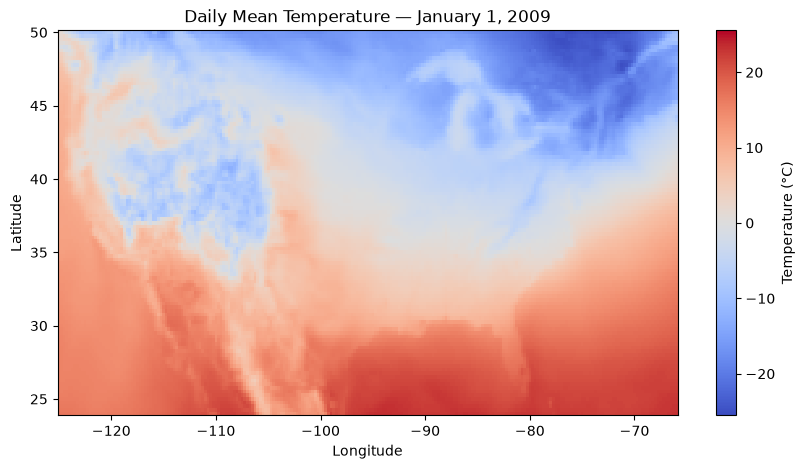

In [5]:
# Draw a temperature map for this day.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

day0.plot(
    ax=ax,
    cmap="coolwarm",
    cbar_kwargs={"label": "Temperature (°C)"}
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Daily Mean Temperature — January 1, 2009")


On this day, the northern part of the map looks colder than the southern part.

### Try west-east and south-north lines

Text(0.5, 1.0, 'Temperature Along 33.75°N — January 1, 2009')

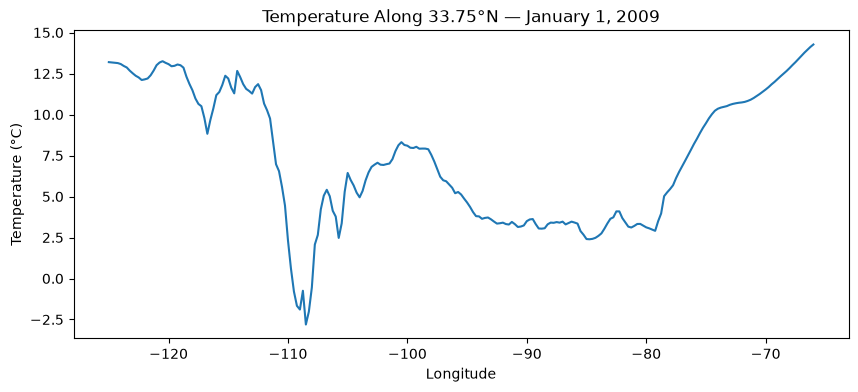

In [6]:
# Keep one latitude and plot temperature from west to east.
temp_line = day0.sel(latitude=33.75, method="nearest")

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(temp_line["longitude"], temp_line)

ax.set_xlabel("Longitude")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Temperature Along 33.75°N — January 1, 2009")


Text(0.5, 1.0, 'Temperature Along 117.75°W — January 1, 2009')

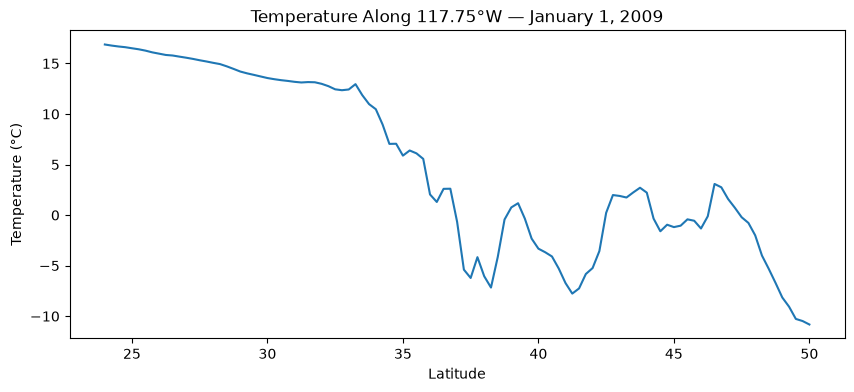

In [7]:
# Keep one longitude and plot temperature from south to north.
temp_ns = day0.sel(longitude=-117.75, method="nearest")

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(temp_ns["latitude"], temp_ns)

ax.set_xlabel("Latitude")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Temperature Along 117.75°W — January 1, 2009")


I tried two lines through the grid point near Irvine (33.75 N, 117.75 W).

- Going west to east, the temperature goes up and down, with a low near 108 W.
- Going south to north, it generally gets colder, although there are some bumps.

I was playing around with different plots to understand the data. These lines show different places on January 1, 2009; they are not Irvine's temperature over time.

## 3. Look at the point near Irvine

I use the grid point at 33.75 N, 117.75 W. It is near Irvine, but it is a grid value rather than a weather-station measurement.

In [8]:
# Pick the grid point near Irvine.
T_irvine = T2M_C.sel(
    latitude=33.75,
    longitude=-117.75,
    method="nearest"
)

T_irvine


<xarray.DataArray 't2m' (valid_time: 730)> Size: 3kB
dask.array<getitem, shape=(730,), dtype=float32, chunksize=(62,), chunktype=numpy.ndarray>
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
    number      int64 8B 0
    latitude    float64 8B 33.75
    longitude   float64 8B -117.8
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      24885
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    degC
    standard_name:                            unknown
    GRIB_surface:                             0.0

Text(0.5, 1.0, 'Daily Mean Temperature Near Irvine — 2009–2010')

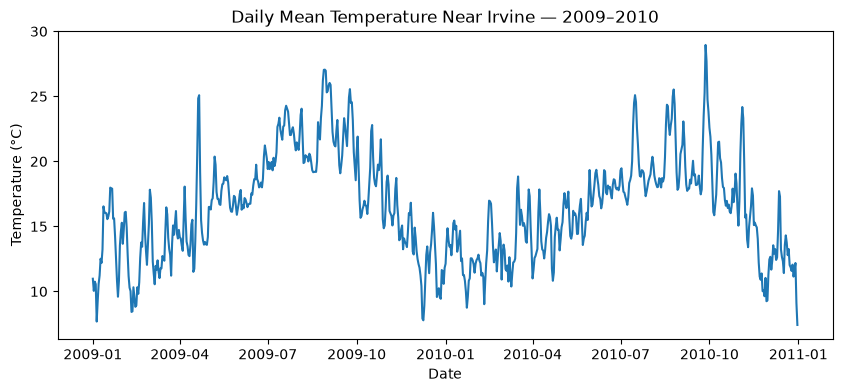

In [9]:
# Plot temperature over time at this point.
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(T_irvine["valid_time"], T_irvine)

ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Daily Mean Temperature Near Irvine — 2009–2010")


Summer is generally warmer and winter is cooler. There are also quite a few changes from one day to the next.

### Try 3-day and 7-day averages

Each average includes today and the previous days. Here I am just plotting them to see the pattern.

In [10]:
# Take the average of today and the previous two days.
T_irvine_3day = T_irvine.rolling(valid_time=3).mean()

T_irvine_3day


<xarray.DataArray 't2m' (valid_time: 730)> Size: 3kB
dask.array<truediv, shape=(730,), dtype=float32, chunksize=(62,), chunktype=numpy.ndarray>
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
    number      int64 8B 0
    latitude    float64 8B 33.75
    longitude   float64 8B -117.8
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      24885
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    degC
    standard_name:                            unknown
    GRIB_surface:                             0.0

In [11]:
# Take the average of today and the previous six days.
T_irvine_7day = T_irvine.rolling(valid_time=7).mean()

T_irvine_7day


<xarray.DataArray 't2m' (valid_time: 730)> Size: 3kB
dask.array<truediv, shape=(730,), dtype=float32, chunksize=(65,), chunktype=numpy.ndarray>
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
    number      int64 8B 0
    latitude    float64 8B 33.75
    longitude   float64 8B -117.8
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      24885
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    degC
    standard_name:                            unknown
    GRIB_surface:                             0.0

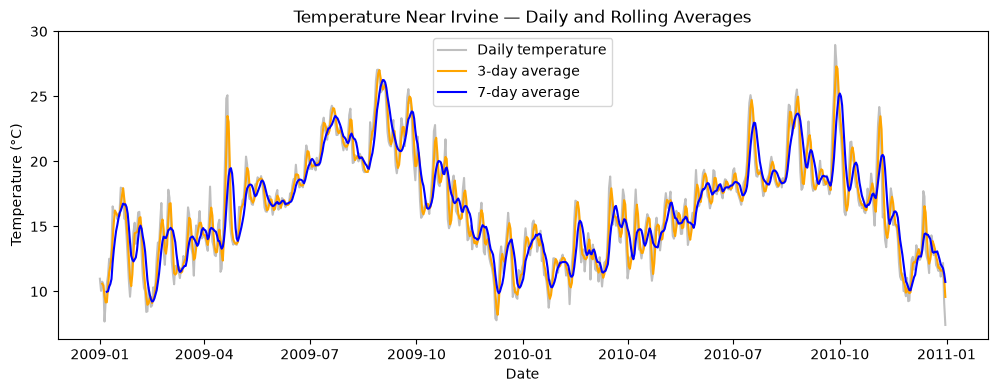

In [12]:
# Plot the daily temperatures and both averages together.
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(T_irvine["valid_time"], T_irvine,
        color="gray", alpha=0.5, label="Daily temperature")

ax.plot(T_irvine_3day["valid_time"], T_irvine_3day,
        color="orange", label="3-day average")

ax.plot(T_irvine_7day["valid_time"], T_irvine_7day,
        color="blue", label="7-day average")

ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Temperature Near Irvine — Daily and Rolling Averages")
ax.legend()


The 7-day average looks smoother than the 3-day average. Both make the seasonal pattern easier to see, but the 7-day line reacts more slowly to sudden changes.

## 4. Make a daily table and a simple baseline

My first guess is that tomorrow will have the same temperature as today. This is called persistence. I also make a column for tomorrow's real temperature so I can check the prediction.

In [13]:
# Put the temperature series into a table.
import pandas as pd

df = pd.DataFrame({
    "today_temp": T_irvine.to_series()
})

df.head()


,today_temp
valid_time,
2009-01-01,10.976807
2009-01-02,10.043762
2009-01-03,10.752289
2009-01-04,10.557648
2009-01-05,7.683075


In [14]:
# Move the next day's temperature into this row.
df["tomorrow_temp"] = df["today_temp"].shift(-1)

df.head()


,today_temp,tomorrow_temp
valid_time,,
2009-01-01,10.976807,10.043762
2009-01-02,10.043762,10.752289
2009-01-03,10.752289,10.557648
2009-01-04,10.557648,7.683075
2009-01-05,7.683075,9.233704


In [15]:
# My first guess: tomorrow will be the same as today.
df["persistence_pred"] = df["today_temp"]

df[["today_temp", "tomorrow_temp", "persistence_pred"]].head()


,today_temp,tomorrow_temp,persistence_pred
valid_time,,,
2009-01-01,10.976807,10.043762,10.976807
2009-01-02,10.043762,10.752289,10.043762
2009-01-03,10.752289,10.557648,10.752289
2009-01-04,10.557648,7.683075,10.557648
2009-01-05,7.683075,9.233704,7.683075


In [16]:
# Check the last few rows.
df.tail()


,today_temp,tomorrow_temp,persistence_pred
valid_time,,,
2010-12-27,11.141174,11.606323,11.141174
2010-12-28,11.606323,12.185303,11.606323
2010-12-29,12.185303,9.120850,12.185303
2010-12-30,9.120850,7.422546,9.120850
2010-12-31,7.422546,NaN,7.422546


In [17]:
# Remove the last row because tomorrow's temperature is missing.
df_model = df.dropna(subset=["tomorrow_temp"]).copy()


In [18]:
# Check how many rows are left.
print("Original rows:", len(df))
print("Rows with a target:", len(df_model))


Original rows: 730
Rows with a target: 729


In [19]:
# Add the date I am trying to predict.
df_model["target_date"] = df_model.index + pd.Timedelta(days=1)


In [20]:
# Check the dates next to the temperatures.
df_model[["target_date", "today_temp", "tomorrow_temp"]].head()


,target_date,today_temp,tomorrow_temp
valid_time,,,
2009-01-01,2009-01-02,10.976807,10.043762
2009-01-02,2009-01-03,10.043762,10.752289
2009-01-03,2009-01-04,10.752289,10.557648
2009-01-04,2009-01-05,10.557648,7.683075
2009-01-05,2009-01-06,7.683075,9.233704


## 5. Split the data by date

I use the date I am predicting (`target_date`) to split the rows:

- Training: target dates in 2009.
- Validation: January-June 2010.
- Final test: July-December 2010.

I keep the dates in order because I want to predict later days using earlier data.

In [21]:
# Use 2009 target dates for training.
train = df_model[df_model["target_date"] < "2010-01-01"].copy()


In [22]:
# Use January-June for validation.
validation = df_model[
    (df_model["target_date"] >= "2010-01-01") &
    (df_model["target_date"] < "2010-07-01")
].copy()


In [23]:
# Save July-December for the final test.
test = df_model[df_model["target_date"] >= "2010-07-01"].copy()


In [24]:
# Check the sizes of the three groups.
print("Training:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))


Training: 364
Validation: 181
Test: 184


### Check the persistence errors

I use two scores to compare predictions with the real temperatures:

- MAE: the average size of the error, ignoring its sign.
- RMSE: square the errors, take their mean, then take the square root. Bigger errors affect this score more.

Both are in degrees Celsius. Lower is better. I use validation data for now and leave the final test for later.

In [25]:
# Find the average absolute error.
errors = validation["persistence_pred"] - validation["tomorrow_temp"]

mae = errors.abs().mean()

print("Persistence validation MAE:", mae)


Persistence validation MAE: 0.90098965


In [26]:
# Square the errors, average them, and take the square root.
mse = (errors ** 2).mean()

rmse = mse ** 0.5

print("Persistence validation RMSE:", rmse)


Persistence validation RMSE: 1.1478524


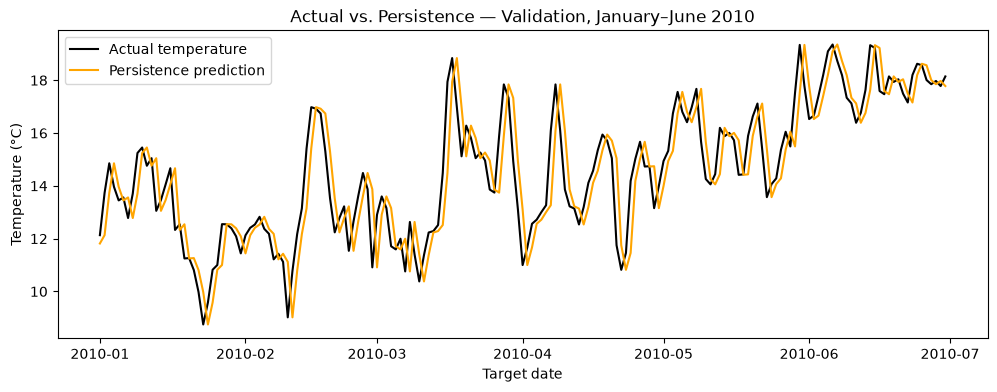

In [27]:
# Plot the real temperature and my baseline prediction.
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(validation["target_date"], validation["tomorrow_temp"],
        color="black", label="Actual temperature")

ax.plot(validation["target_date"], validation["persistence_pred"],
        color="orange", label="Persistence prediction")

ax.set_xlabel("Target date")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Actual vs. Persistence — Validation, January–June 2010")
ax.legend()


Persistence has an MAE of about 0.90 C and an RMSE of 1.15 C for January-June 2010. Its line follows the temperature pattern but is one day behind. It misses some sudden changes. This is my starting point for comparing other models.

## 6. Try linear regression

I first use just today's temperature as the input. The model learns a slope and an intercept from the training data.

In [28]:
# Use today's temperature as X and tomorrow's as y.
X_train = train[["today_temp"]]

y_train = train["tomorrow_temp"]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)


X_train shape: (364, 1)
y_train shape: (364,)


In [29]:
# Train the model and look at its slope and intercept.
from sklearn.linear_model import LinearRegression

reg = LinearRegression()

reg.fit(X_train, y_train)

print("Slope:", reg.coef_[0])
print("Intercept:", reg.intercept_)


Slope: 0.953983
Intercept: 0.7772236


In [30]:
# Make predictions for the validation dates.
X_val = validation[["today_temp"]]

validation["linear_pred"] = reg.predict(X_val)

validation[["tomorrow_temp", "persistence_pred", "linear_pred"]].head()


,tomorrow_temp,persistence_pred,linear_pred
valid_time,,,
2009-12-31,12.131531,11.815826,12.049321
2010-01-01,13.732849,12.131531,12.350498
2010-01-02,14.855377,13.732849,13.878128
2010-01-03,13.962616,14.855377,14.949001
2010-01-04,13.447449,13.962616,14.097322


In [31]:
# Check whether linear regression has smaller errors.
linear_errors = validation["linear_pred"] - validation["tomorrow_temp"]

linear_mae = linear_errors.abs().mean()
linear_rmse = ((linear_errors ** 2).mean()) ** 0.5

print("Persistence MAE:", mae)
print("Linear regression MAE:", linear_mae)

print("Persistence RMSE:", rmse)
print("Linear regression RMSE:", linear_rmse)


Persistence MAE: 0.90098965
Linear regression MAE: 0.87300825
Persistence RMSE: 1.1478524
Linear regression RMSE: 1.1292427


The linear regression model has an MAE of 0.873 C and an RMSE of 1.129 C. This is a little better than persistence on these validation dates. I have not calculated the final test scores yet.

## 7. Try three validation periods

One split might not tell the whole story. I want to check whether the model works similarly in different months.

| Round | Training target dates | Validation target dates |
| --- | --- | --- |
| 1 | 2009 | Jan-Feb 2010 |
| 2 | 2009-Feb 2010 | Mar-Apr 2010 |
| 3 | 2009-Apr 2010 | May-Jun 2010 |

I train a new model each round. As I move forward, I can add the earlier validation months to the training data. Training dates always come before that round's validation dates. July-December stays as the final test.

### Round 1: January-February

In [32]:
# Move forward to the next training and validation dates.
train_1 = df_model[
    df_model["target_date"] < "2010-01-01"
].copy()

val_1 = df_model[
    (df_model["target_date"] >= "2010-01-01") &
    (df_model["target_date"] < "2010-03-01")
].copy()


print("Training samples:", len(train_1))
print("Validation samples:", len(val_1))


Training samples: 364
Validation samples: 59


In [33]:
# Train on the earlier dates using these temperature columns.
X_train_1 = train_1[["today_temp"]]
y_train_1 = train_1["tomorrow_temp"]

reg_1 = LinearRegression()
reg_1.fit(X_train_1, y_train_1)

print("Slope:", reg_1.coef_[0])
print("Intercept:", reg_1.intercept_)


Slope: 0.953983
Intercept: 0.7772236


In [34]:
# Predict the next-day temperatures for this validation period.
X_val_1 = val_1[["today_temp"]]
val_1["linear_pred"] = reg_1.predict(X_val_1)

val_1["persistence_pred"] = val_1["today_temp"]

val_1[["tomorrow_temp", "persistence_pred", "linear_pred"]].head()


,tomorrow_temp,persistence_pred,linear_pred
valid_time,,,
2009-12-31,12.131531,11.815826,12.049321
2010-01-01,13.732849,12.131531,12.350498
2010-01-02,14.855377,13.732849,13.878128
2010-01-03,13.962616,14.855377,14.949001
2010-01-04,13.447449,13.962616,14.097322


In [35]:
# Compare the predictions with the real temperatures using MAE and RMSE.
persistence_errors_1 = val_1["persistence_pred"] - val_1["tomorrow_temp"]
linear_errors_1 = val_1["linear_pred"] - val_1["tomorrow_temp"]

persistence_mae_1 = persistence_errors_1.abs().mean()
linear_mae_1 = linear_errors_1.abs().mean()

persistence_rmse_1 = ((persistence_errors_1 ** 2).mean()) ** 0.5
linear_rmse_1 = ((linear_errors_1 ** 2).mean()) ** 0.5

print("Persistence MAE:", persistence_mae_1)
print("Linear regression MAE:", linear_mae_1)
print("Persistence RMSE:", persistence_rmse_1)
print("Linear regression RMSE:", linear_rmse_1)


Persistence MAE: 0.8710689
Linear regression MAE: 0.84808177
Persistence RMSE: 1.0997553
Linear regression RMSE: 1.0968363


Linear regression is a little better in January-February, but the RMSE difference is very small. Next I will try March-April.

### Round 2: March-April

In [36]:
# Move forward to the next training and validation dates.
train_2 = df_model[
    df_model["target_date"] < "2010-03-01"
].copy()

val_2 = df_model[
    (df_model["target_date"] >= "2010-03-01") &
    (df_model["target_date"] < "2010-05-01")
].copy()

print("Training samples:", len(train_2))
print("Validation samples:", len(val_2))


Training samples: 423
Validation samples: 61


In [37]:
# Train on the earlier dates using these temperature columns.
X_train_2 = train_2[["today_temp"]]
y_train_2 = train_2["tomorrow_temp"]

reg_2 = LinearRegression()
reg_2.fit(X_train_2, y_train_2)

print("Slope:", reg_2.coef_[0])
print("Intercept:", reg_2.intercept_)


Slope: 0.95602006
Intercept: 0.7159376


In [38]:
# Predict the next-day temperatures for this validation period.
X_val_2 = val_2[["today_temp"]]
val_2["linear_pred"] = reg_2.predict(X_val_2)

val_2["persistence_pred"] = val_2["today_temp"]

val_2[["tomorrow_temp", "persistence_pred", "linear_pred"]].head()


,tomorrow_temp,persistence_pred,linear_pred
valid_time,,,
2010-02-28,12.905334,10.912140,11.148162
2010-03-01,13.599060,12.905334,13.053697
2010-03-02,13.159821,13.599060,13.716911
2010-03-03,11.712189,13.159821,13.296990
2010-03-04,11.591949,11.712189,11.913025


In [39]:
# Compare the predictions with the real temperatures using MAE and RMSE.
persistence_errors_2 = val_2["persistence_pred"] - val_2["tomorrow_temp"]
linear_errors_2 = val_2["linear_pred"] - val_2["tomorrow_temp"]

persistence_mae_2 = persistence_errors_2.abs().mean()
linear_mae_2 = linear_errors_2.abs().mean()

persistence_rmse_2 = ((persistence_errors_2 ** 2).mean()) ** 0.5
linear_rmse_2 = ((linear_errors_2 ** 2).mean()) ** 0.5

print("Persistence MAE:", persistence_mae_2)
print("Linear regression MAE:", linear_mae_2)
print("Persistence RMSE:", persistence_rmse_2)
print("Linear regression RMSE:", linear_rmse_2)


Persistence MAE: 1.0920886
Linear regression MAE: 1.0567979
Persistence RMSE: 1.3705996
Linear regression RMSE: 1.3407522


Linear regression is also a little better in March-April. Both models have bigger errors than in January-February.

### Round 3: May-June

In [40]:
# Move forward to the next training and validation dates.
train_3 = df_model[
    df_model["target_date"] < "2010-05-01"
].copy()

val_3 = df_model[
    (df_model["target_date"] >= "2010-05-01") &
    (df_model["target_date"] < "2010-07-01")
].copy()

print("Training samples:", len(train_3))
print("Validation samples:", len(val_3))


Training samples: 484
Validation samples: 61


In [41]:
# Train on the earlier dates using these temperature columns.
X_train_3 = train_3[["today_temp"]]
y_train_3 = train_3["tomorrow_temp"]

reg_3 = LinearRegression()
reg_3.fit(X_train_3, y_train_3)

print("Slope:", reg_3.coef_[0])
print("Intercept:", reg_3.intercept_)


Slope: 0.95052284
Intercept: 0.797122


In [42]:
# Predict the next-day temperatures for this validation period.
X_val_3 = val_3[["today_temp"]]
val_3["linear_pred"] = reg_3.predict(X_val_3)

val_3["persistence_pred"] = val_3["today_temp"]

val_3[["tomorrow_temp", "persistence_pred", "linear_pred"]].head()


,tomorrow_temp,persistence_pred,linear_pred
valid_time,,,
2010-04-30,14.937927,13.991211,14.096087
2010-05-01,15.324524,14.937927,14.995963
2010-05-02,16.744781,15.324524,15.363432
2010-05-03,17.558014,16.744781,16.713419
2010-05-04,16.802185,17.558014,17.486416


In [43]:
# Compare the predictions with the real temperatures using MAE and RMSE.
persistence_errors_3 = val_3["persistence_pred"] - val_3["tomorrow_temp"]
linear_errors_3 = val_3["linear_pred"] - val_3["tomorrow_temp"]

persistence_mae_3 = persistence_errors_3.abs().mean()
linear_mae_3 = linear_errors_3.abs().mean()

persistence_rmse_3 = ((persistence_errors_3 ** 2).mean()) ** 0.5
linear_rmse_3 = ((linear_errors_3 ** 2).mean()) ** 0.5


print("Persistence MAE:", persistence_mae_3)
print("Linear regression MAE:", linear_mae_3)
print("Persistence RMSE:", persistence_rmse_3)
print("Linear regression RMSE:", linear_rmse_3)


Persistence MAE: 0.73883057
Linear regression MAE: 0.7171746
Persistence RMSE: 0.9279794
Linear regression RMSE: 0.9083651


### Compare the three rounds

In [44]:
# Put the three rounds into a table.
results = pd.DataFrame({
    "Validation period": ["Jan-Feb 2010", "Mar-Apr 2010", "May-Jun 2010"],
    "Persistence MAE": [
        persistence_mae_1, persistence_mae_2, persistence_mae_3
    ],
    "Linear MAE": [
        linear_mae_1, linear_mae_2, linear_mae_3
    ],
    "Persistence RMSE": [
        persistence_rmse_1, persistence_rmse_2, persistence_rmse_3
    ],
    "Linear RMSE": [
        linear_rmse_1, linear_rmse_2, linear_rmse_3
    ]
})

results.round(3)


,Validation period,Persistence MAE,Linear MAE,Persistence RMSE,Linear RMSE
0,Jan-Feb 2010,0.871,0.848,1.100,1.097
1,Mar-Apr 2010,1.092,1.057,1.371,1.341
2,May-Jun 2010,0.739,0.717,0.928,0.908


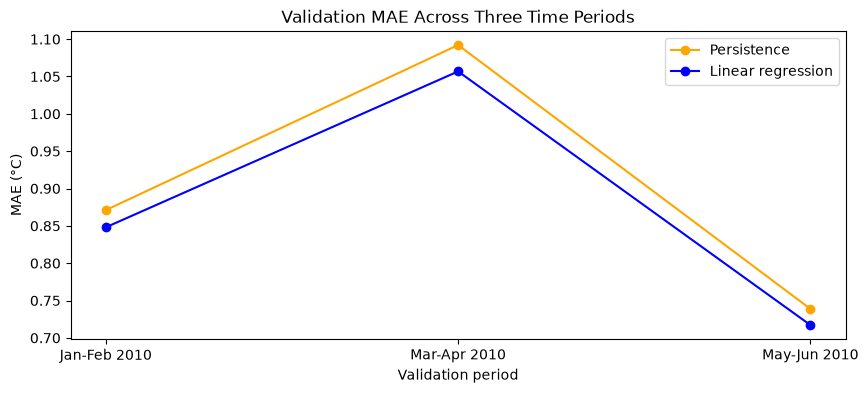

In [45]:
# Plot MAE for the two models.
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(results["Validation period"], results["Persistence MAE"],
        marker="o", color="orange", label="Persistence")

ax.plot(results["Validation period"], results["Linear MAE"],
        marker="o", color="blue", label="Linear regression")

ax.set_xlabel("Validation period")
ax.set_ylabel("MAE (°C)")
ax.set_title("Validation MAE Across Three Time Periods")
ax.legend()


## 8. Add 3-day and 7-day averages

Now I try using the averages as model inputs, along with today's temperature. The 3-day average uses today and the previous two days. The 7-day average uses today and the previous six days. Neither uses tomorrow's temperature.

The first six rows do not have a full 7-day history, so I remove them. I also retrain the today-only model on those same remaining rows for a fair comparison.

In [46]:
# Add averages that use only today and earlier days.
df_model["temp_3day"] = df_model["today_temp"].rolling(window=3).mean()
df_model["temp_7day"] = df_model["today_temp"].rolling(window=7).mean()

df_model[["today_temp", "temp_3day", "temp_7day", "tomorrow_temp"]].head(10)


,today_temp,temp_3day,temp_7day,tomorrow_temp
valid_time,,,,
2009-01-01,10.976807,NaN,NaN,10.043762
2009-01-02,10.043762,NaN,NaN,10.752289
2009-01-03,10.752289,10.590953,NaN,10.557648
2009-01-04,10.557648,10.451233,NaN,7.683075
2009-01-05,7.683075,9.664337,NaN,9.233704
2009-01-06,9.233704,9.158142,NaN,10.581696
2009-01-07,10.581696,9.166158,9.975568,11.220703
2009-01-08,11.220703,10.345367,10.010411,12.512634
2009-01-09,12.512634,11.438344,10.363107,12.194153


In [47]:
# Drop rows without enough days for both averages.
df_rolling = df_model.dropna(
    subset=["temp_3day", "temp_7day"]
).copy()

print("Original rows:", len(df_model))
print("Rows with rolling features:", len(df_rolling))


Original rows: 729
Rows with rolling features: 723


### Round 1: January-February

In [48]:
# Keep earlier dates for training and the next two months for validation.
train_rolling_1 = df_rolling[
    df_rolling["target_date"] < "2010-01-01"
].copy()

val_rolling_1 = df_rolling[
    (df_rolling["target_date"] >= "2010-01-01") &
    (df_rolling["target_date"] < "2010-03-01")
].copy()

print("Training samples:", len(train_rolling_1))
print("Validation samples:", len(val_rolling_1))


Training samples: 358
Validation samples: 59


In [49]:
# Train on the earlier dates using these temperature columns.
features = ["today_temp", "temp_3day", "temp_7day"]
X_train_rolling_1 = train_rolling_1[features]
y_train_rolling_1 = train_rolling_1["tomorrow_temp"]

reg_rolling_1 = LinearRegression()
reg_rolling_1.fit(X_train_rolling_1, y_train_rolling_1)

print(pd.Series(reg_rolling_1.coef_, index=features))
print("Intercept:", reg_rolling_1.intercept_)


today_temp    1.346324
temp_3day    -0.682535
temp_7day     0.298312
dtype: float64
Intercept: 0.6450162978012095


In [50]:
# Predict the next-day temperatures for this validation period.
X_val_rolling_1 = val_rolling_1[features]

val_rolling_1["rolling_pred"] = reg_rolling_1.predict(X_val_rolling_1)

val_rolling_1[["tomorrow_temp", "rolling_pred"]].head()


,tomorrow_temp,rolling_pred
valid_time,,
2009-12-31,12.131531,12.016786
2010-01-01,13.732849,12.391815
2010-01-02,14.855377,14.008685
2010-01-03,13.962616,15.059548
2010-01-04,13.447449,13.539825


In [51]:
# Compare the predictions with the real temperatures using MAE and RMSE.
rolling_errors_1 = (
    val_rolling_1["rolling_pred"] - val_rolling_1["tomorrow_temp"]
)

rolling_mae_1 = rolling_errors_1.abs().mean()
rolling_rmse_1 = ((rolling_errors_1 ** 2).mean()) ** 0.5

print("Rolling model MAE:", rolling_mae_1)
print("Rolling model RMSE:", rolling_rmse_1)


Rolling model MAE: 0.8148678488772908
Rolling model RMSE: 1.059334177899038


In [52]:
# Train on the earlier dates using these temperature columns.
reg_today_1 = LinearRegression()
reg_today_1.fit(
    train_rolling_1[["today_temp"]],
    train_rolling_1["tomorrow_temp"]
)

val_rolling_1["today_only_pred"] = reg_today_1.predict(
    val_rolling_1[["today_temp"]]
)

today_errors_1 = (
    val_rolling_1["today_only_pred"] - val_rolling_1["tomorrow_temp"]
)

print("Today-only MAE:", today_errors_1.abs().mean())
print("Today-only RMSE:", ((today_errors_1 ** 2).mean()) ** 0.5)


Today-only MAE: 0.8489252
Today-only RMSE: 1.0986683


### Round 2: March-April

In [53]:
# Keep earlier dates for training and the next two months for validation.
train_rolling_2 = df_rolling[
    df_rolling["target_date"] < "2010-03-01"
].copy()

val_rolling_2 = df_rolling[
    (df_rolling["target_date"] >= "2010-03-01") &
    (df_rolling["target_date"] < "2010-05-01")
].copy()

print("Training samples:", len(train_rolling_2))
print("Validation samples:", len(val_rolling_2))


Training samples: 417
Validation samples: 61


In [54]:
# Train on the earlier dates using these temperature columns.
reg_rolling_2 = LinearRegression()
reg_rolling_2.fit(
    train_rolling_2[features],
    train_rolling_2["tomorrow_temp"]
)

reg_today_2 = LinearRegression()
reg_today_2.fit(
    train_rolling_2[["today_temp"]],
    train_rolling_2["tomorrow_temp"]
)

print(pd.Series(reg_rolling_2.coef_, index=features))
print("Intercept:", reg_rolling_2.intercept_)


today_temp    1.345137
temp_3day    -0.673310
temp_7day     0.292204
dtype: float64
Intercept: 0.5896038577976466


In [55]:
# Predict the next-day temperatures for this validation period.
val_rolling_2["rolling_pred"] = reg_rolling_2.predict(
    val_rolling_2[features]
)

val_rolling_2["today_only_pred"] = reg_today_2.predict(
    val_rolling_2[["today_temp"]]
)

val_rolling_2[
    ["tomorrow_temp", "today_only_pred", "rolling_pred"]
].head()


,tomorrow_temp,today_only_pred,rolling_pred
valid_time,,,
2010-02-28,12.905334,11.158146,10.223507
2010-03-01,13.599060,13.061863,13.246274
2010-03-02,13.159821,13.724445,14.326536
2010-03-03,11.712189,13.304924,13.252477
2010-03-04,11.591949,11.922279,11.493691


In [56]:
# Compare the predictions with the real temperatures using MAE and RMSE.
rolling_errors_2 = (
    val_rolling_2["rolling_pred"] - val_rolling_2["tomorrow_temp"]
)
today_errors_2 = (
    val_rolling_2["today_only_pred"] - val_rolling_2["tomorrow_temp"]
)

rolling_mae_2 = rolling_errors_2.abs().mean()
rolling_rmse_2 = ((rolling_errors_2 ** 2).mean()) ** 0.5

today_mae_2 = today_errors_2.abs().mean()
today_rmse_2 = ((today_errors_2 ** 2).mean()) ** 0.5

print("Today-only MAE:", today_mae_2)
print("Rolling model MAE:", rolling_mae_2)
print("Today-only RMSE:", today_rmse_2)
print("Rolling model RMSE:", rolling_rmse_2)


Today-only MAE: 1.0563002
Rolling model MAE: 0.9881783070125774
Today-only RMSE: 1.3404932
Rolling model RMSE: 1.2643482710739706


### Round 3: May-June

In [57]:
# Keep earlier dates for training and the next two months for validation.
train_rolling_3 = df_rolling[
    df_rolling["target_date"] < "2010-05-01"
].copy()

val_rolling_3 = df_rolling[
    (df_rolling["target_date"] >= "2010-05-01") &
    (df_rolling["target_date"] < "2010-07-01")
].copy()

print("Training samples:", len(train_rolling_3))
print("Validation samples:", len(val_rolling_3))


Training samples: 478
Validation samples: 61


In [58]:
# Train on the earlier dates using these temperature columns.
reg_rolling_3 = LinearRegression()
reg_rolling_3.fit(
    train_rolling_3[features],
    train_rolling_3["tomorrow_temp"]
)

reg_today_3 = LinearRegression()
reg_today_3.fit(
    train_rolling_3[["today_temp"]],
    train_rolling_3["tomorrow_temp"]
)

print(pd.Series(reg_rolling_3.coef_, index=features))
print("Intercept:", reg_rolling_3.intercept_)


today_temp    1.321607
temp_3day    -0.660164
temp_7day     0.298087
dtype: float64
Intercept: 0.6594990467634911


In [59]:
# Predict the next-day temperatures for this validation period.
val_rolling_3["rolling_pred"] = reg_rolling_3.predict(
    val_rolling_3[features]
)

val_rolling_3["today_only_pred"] = reg_today_3.predict(
    val_rolling_3[["today_temp"]]
)

val_rolling_3[
    ["tomorrow_temp", "today_only_pred", "rolling_pred"]
].head()


,tomorrow_temp,today_only_pred,rolling_pred
valid_time,,,
2010-04-30,14.937927,14.102639,14.254765
2010-05-01,15.324524,15.001667,15.494989
2010-05-02,16.744781,15.368790,15.541266
2010-05-03,17.558014,16.717506,16.858180
2010-05-04,16.802185,17.489773,17.476784


In [60]:
# Compare the predictions with the real temperatures using MAE and RMSE.
rolling_errors_3 = (
    val_rolling_3["rolling_pred"] - val_rolling_3["tomorrow_temp"]
)
today_errors_3 = (
    val_rolling_3["today_only_pred"] - val_rolling_3["tomorrow_temp"]
)

rolling_mae_3 = rolling_errors_3.abs().mean()
rolling_rmse_3 = ((rolling_errors_3 ** 2).mean()) ** 0.5

today_mae_3 = today_errors_3.abs().mean()
today_rmse_3 = ((today_errors_3 ** 2).mean()) ** 0.5

print("Today-only MAE:", today_mae_3)
print("Rolling model MAE:", rolling_mae_3)
print("Today-only RMSE:", today_rmse_3)
print("Rolling model RMSE:", rolling_rmse_3)


Today-only MAE: 0.7163546
Rolling model MAE: 0.6651242052947458
Today-only RMSE: 0.9075612
Rolling model RMSE: 0.861821073675318


Using both rolling averages gives lower MAE and RMSE in all three rounds. I used the same training rows and validation dates for each pair of models, so this seems worth keeping for now.

### Compare the scores

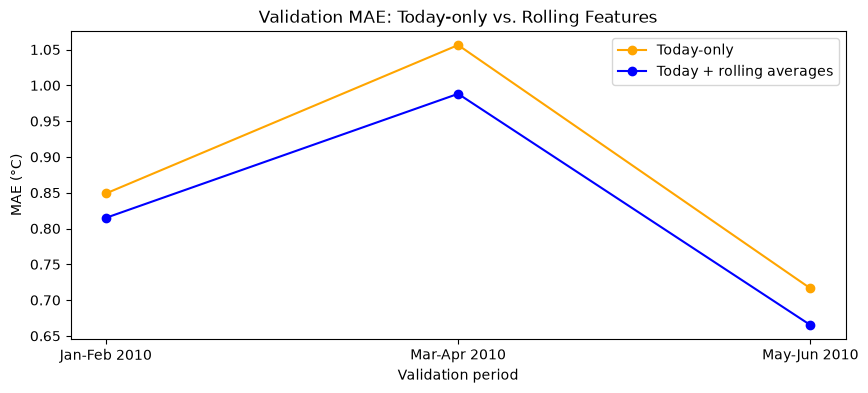

In [61]:
# Plot MAE for each round.
today_mae_1 = today_errors_1.abs().mean()

periods = ["Jan-Feb 2010", "Mar-Apr 2010", "May-Jun 2010"]

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(periods, [today_mae_1, today_mae_2, today_mae_3],
        marker="o", color="orange", label="Today-only")

ax.plot(periods, [rolling_mae_1, rolling_mae_2, rolling_mae_3],
        marker="o", color="blue", label="Today + rolling averages")

ax.set_xlabel("Validation period")
ax.set_ylabel("MAE (°C)")
ax.set_title("Validation MAE: Today-only vs. Rolling Features")
ax.legend()


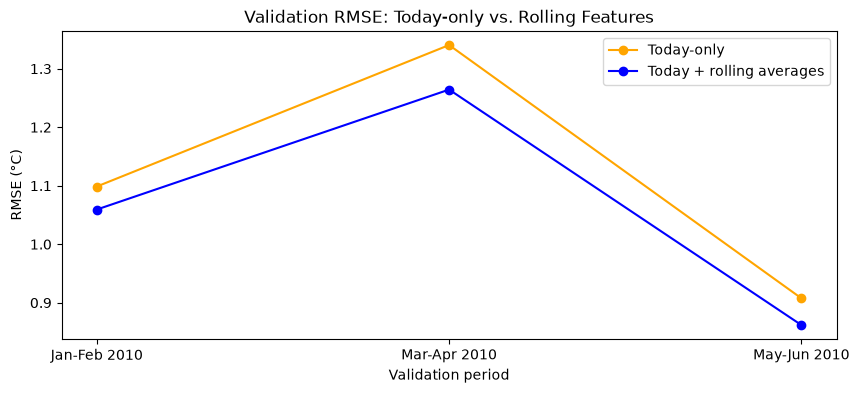

In [62]:
# Plot RMSE for each round.
today_rmse_1 = ((today_errors_1 ** 2).mean()) ** 0.5

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(periods, [today_rmse_1, today_rmse_2, today_rmse_3],
        marker="o", color="orange", label="Today-only")

ax.plot(periods, [rolling_rmse_1, rolling_rmse_2, rolling_rmse_3],
        marker="o", color="blue", label="Today + rolling averages")

ax.set_xlabel("Validation period")
ax.set_ylabel("RMSE (°C)")
ax.set_title("Validation RMSE: Today-only vs. Rolling Features")
ax.legend()


### Put all validation days together

I join the daily errors from the three rounds, then calculate MAE and RMSE. I do not just average the three RMSE values.

In [63]:
# Join the daily errors from all three rounds.
today_errors_all = pd.concat([
    today_errors_1, today_errors_2, today_errors_3
])

rolling_errors_all = pd.concat([
    rolling_errors_1, rolling_errors_2, rolling_errors_3
])

print("Today-only MAE:", today_errors_all.abs().mean())
print("Rolling model MAE:", rolling_errors_all.abs().mean())

print("Today-only RMSE:", ((today_errors_all ** 2).mean()) ** 0.5)
print("Rolling model RMSE:", ((rolling_errors_all ** 2).mean()) ** 0.5)


Today-only MAE: 0.8741355
Rolling model MAE: 0.8228102559917506
Today-only RMSE: 1.1298883
Rolling model RMSE: 1.0746429037035512


Over all 181 validation days, MAE goes from 0.874 C to 0.823 C and RMSE goes from 1.130 C to 1.075 C when I add both averages. These predictions come from three models trained at different times. I have not evaluated the final test period.

## 9. Do I need both averages?

I try adding only the 3-day average, then only the 7-day average. I keep the same training rows and validation dates as before.

### Round 1: January-February

In [64]:
# Train on the earlier dates using these temperature columns.
features_3day = ["today_temp", "temp_3day"]

reg_3day_1 = LinearRegression()
reg_3day_1.fit(
    train_rolling_1[features_3day],
    train_rolling_1["tomorrow_temp"]
)

val_rolling_1["pred_3day"] = reg_3day_1.predict(
    val_rolling_1[features_3day]
)


In [65]:
# Compare the predictions with the real temperatures using MAE and RMSE.
errors_3day_1 = (
    val_rolling_1["pred_3day"] - val_rolling_1["tomorrow_temp"]
)

mae_3day_1 = errors_3day_1.abs().mean()
rmse_3day_1 = ((errors_3day_1 ** 2).mean()) ** 0.5

print("Today + 3-day MAE:", mae_3day_1)
print("Today + 3-day + 7-day MAE:", rolling_mae_1)

print("Today + 3-day RMSE:", rmse_3day_1)
print("Today + 3-day + 7-day RMSE:", rolling_rmse_1)


Today + 3-day MAE: 0.8689313959186459
Today + 3-day + 7-day MAE: 0.8148678488772908
Today + 3-day RMSE: 1.0891218553312805
Today + 3-day + 7-day RMSE: 1.059334177899038


In [66]:
# Train on the earlier dates using these temperature columns.
features_7day = ["today_temp", "temp_7day"]

reg_7day_1 = LinearRegression()
reg_7day_1.fit(
    train_rolling_1[features_7day],
    train_rolling_1["tomorrow_temp"]
)

val_rolling_1["pred_7day"] = reg_7day_1.predict(
    val_rolling_1[features_7day]
)


In [67]:
# Compare the predictions with the real temperatures using MAE and RMSE.
errors_7day_1 = (
    val_rolling_1["pred_7day"] - val_rolling_1["tomorrow_temp"]
)

mae_7day_1 = errors_7day_1.abs().mean()
rmse_7day_1 = ((errors_7day_1 ** 2).mean()) ** 0.5

print("Today + 7-day MAE:", mae_7day_1)
print("Today + 3-day + 7-day MAE:", rolling_mae_1)

print("Today + 7-day RMSE:", rmse_7day_1)
print("Today + 3-day + 7-day RMSE:", rolling_rmse_1)


Today + 7-day MAE: 0.8514022774671388
Today + 3-day + 7-day MAE: 0.8148678488772908
Today + 7-day RMSE: 1.0989307608947674
Today + 3-day + 7-day RMSE: 1.059334177899038


### Round 2: March-April

In [68]:
# Train on the earlier dates using these temperature columns.
reg_3day_2 = LinearRegression()
reg_3day_2.fit(
    train_rolling_2[features_3day],
    train_rolling_2["tomorrow_temp"]
)

val_rolling_2["pred_3day"] = reg_3day_2.predict(
    val_rolling_2[features_3day]
)


In [69]:
# Compare the predictions with the real temperatures using MAE and RMSE.
errors_3day_2 = (
    val_rolling_2["pred_3day"] - val_rolling_2["tomorrow_temp"]
)

mae_3day_2 = errors_3day_2.abs().mean()
rmse_3day_2 = ((errors_3day_2 ** 2).mean()) ** 0.5

print("Today + 3-day MAE:", mae_3day_2)
print("Today + 3-day + 7-day MAE:", rolling_mae_2)

print("Today + 3-day RMSE:", rmse_3day_2)
print("Today + 3-day + 7-day RMSE:", rolling_rmse_2)


Today + 3-day MAE: 1.0264220046310533
Today + 3-day + 7-day MAE: 0.9881783070125774
Today + 3-day RMSE: 1.3203798047179947
Today + 3-day + 7-day RMSE: 1.2643482710739706


In [70]:
# Train on the earlier dates using these temperature columns.
reg_7day_2 = LinearRegression()
reg_7day_2.fit(
    train_rolling_2[features_7day],
    train_rolling_2["tomorrow_temp"]
)

val_rolling_2["pred_7day"] = reg_7day_2.predict(
    val_rolling_2[features_7day]
)


In [71]:
# Compare the predictions with the real temperatures using MAE and RMSE.
errors_7day_2 = (
    val_rolling_2["pred_7day"] - val_rolling_2["tomorrow_temp"]
)

mae_7day_2 = errors_7day_2.abs().mean()
rmse_7day_2 = ((errors_7day_2 ** 2).mean()) ** 0.5

print("Today + 7-day MAE:", mae_7day_2)
print("Today + 3-day + 7-day MAE:", rolling_mae_2)

print("Today + 7-day RMSE:", rmse_7day_2)
print("Today + 3-day + 7-day RMSE:", rolling_rmse_2)


Today + 7-day MAE: 1.0578342606260647
Today + 3-day + 7-day MAE: 0.9881783070125774
Today + 7-day RMSE: 1.3416362496829002
Today + 3-day + 7-day RMSE: 1.2643482710739706


### Round 3: May-June

In [72]:
# Train on the earlier dates using these temperature columns.
reg_3day_3 = LinearRegression()
reg_3day_3.fit(
    train_rolling_3[features_3day],
    train_rolling_3["tomorrow_temp"]
)

val_rolling_3["pred_3day"] = reg_3day_3.predict(
    val_rolling_3[features_3day]
)


In [73]:
# Compare the predictions with the real temperatures using MAE and RMSE.
errors_3day_3 = (
    val_rolling_3["pred_3day"] - val_rolling_3["tomorrow_temp"]
)

mae_3day_3 = errors_3day_3.abs().mean()
rmse_3day_3 = ((errors_3day_3 ** 2).mean()) ** 0.5

print("Today + 3-day MAE:", mae_3day_3)
print("Today + 3-day + 7-day MAE:", rolling_mae_3)

print("Today + 3-day RMSE:", rmse_3day_3)
print("Today + 3-day + 7-day RMSE:", rolling_rmse_3)


Today + 3-day MAE: 0.715191069451912
Today + 3-day + 7-day MAE: 0.6651242052947458
Today + 3-day RMSE: 0.9031634287723107
Today + 3-day + 7-day RMSE: 0.861821073675318


In [74]:
# Train on the earlier dates using these temperature columns.
reg_7day_3 = LinearRegression()
reg_7day_3.fit(
    train_rolling_3[features_7day],
    train_rolling_3["tomorrow_temp"]
)

val_rolling_3["pred_7day"] = reg_7day_3.predict(
    val_rolling_3[features_7day]
)


In [75]:
# Compare the predictions with the real temperatures using MAE and RMSE.
errors_7day_3 = (
    val_rolling_3["pred_7day"] - val_rolling_3["tomorrow_temp"]
)

mae_7day_3 = errors_7day_3.abs().mean()
rmse_7day_3 = ((errors_7day_3 ** 2).mean()) ** 0.5

print("Today + 7-day MAE:", mae_7day_3)
print("Today + 3-day + 7-day MAE:", rolling_mae_3)

print("Today + 7-day RMSE:", rmse_7day_3)
print("Today + 3-day + 7-day RMSE:", rolling_rmse_3)


Today + 7-day MAE: 0.7165281550235538
Today + 3-day + 7-day MAE: 0.6651242052947458
Today + 7-day RMSE: 0.9077781189129862
Today + 3-day + 7-day RMSE: 0.861821073675318


### Compare all four choices

In [76]:
# Put the MAE scores for all four models into one table.
mae_comparison = pd.DataFrame({
    "Validation period": periods,
    "Today-only": [today_mae_1, today_mae_2, today_mae_3],
    "Today + 3-day": [mae_3day_1, mae_3day_2, mae_3day_3],
    "Today + 7-day": [mae_7day_1, mae_7day_2, mae_7day_3],
    "Today + 3-day + 7-day": [
        rolling_mae_1, rolling_mae_2, rolling_mae_3
    ]
})

mae_comparison.round(3)


,Validation period,Today-only,Today + 3-day,Today + 7-day,Today + 3-day + 7-day
0,Jan-Feb 2010,0.849,0.869,0.851,0.815
1,Mar-Apr 2010,1.056,1.026,1.058,0.988
2,May-Jun 2010,0.716,0.715,0.717,0.665


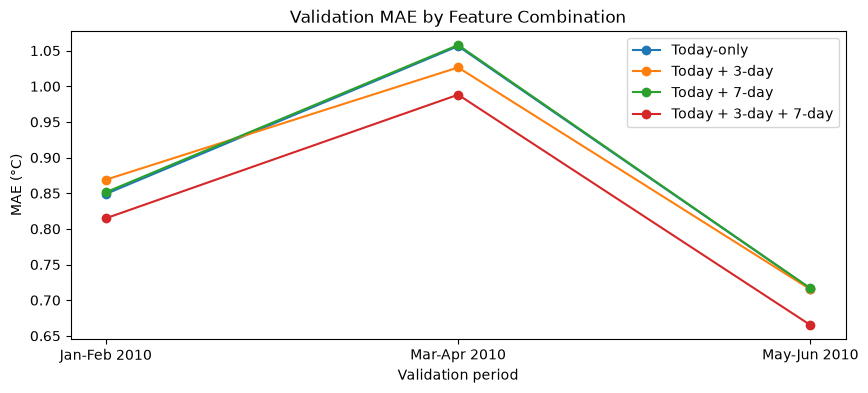

In [77]:
# Plot the four choices together.
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(periods, mae_comparison["Today-only"],
        marker="o", label="Today-only")

ax.plot(periods, mae_comparison["Today + 3-day"],
        marker="o", label="Today + 3-day")

ax.plot(periods, mae_comparison["Today + 7-day"],
        marker="o", label="Today + 7-day")

ax.plot(periods, mae_comparison["Today + 3-day + 7-day"],
        marker="o", label="Today + 3-day + 7-day")

ax.set_xlabel("Validation period")
ax.set_ylabel("MAE (°C)")
ax.set_title("Validation MAE by Feature Combination")
ax.legend()


The model with both averages has the lowest MAE in all three rounds. Adding just the 7-day average barely changes the results. Adding just the 3-day average does not help in every round.

All four models have their largest MAE in March-April. For now, I will keep both averages. This is based on these validation months, so I still need to check the final test later.

## 10. Final test: July-December 2010

I am finishing the temperature-only version here. I chose today's temperature, the 3-day average, and the 7-day average because this combination worked best in all three validation rounds. I will keep this choice fixed for the final test.

I now train once using all available rows with target dates before July 2010, including the earlier validation months. I compare the model with persistence on the same July-December dates.

This is a next-day prediction made after today's daily temperature is available. For each test day, I can use the temperatures already observed, including earlier days in the test period. The rolling averages never use tomorrow's temperature. I do not refit the model during these six months.

### Prepare the final training and test data

In [78]:
# Use all earlier target dates to train the final model.
final_train = df_rolling[df_rolling["target_date"] < "2010-07-01"].copy()
final_test = df_rolling[df_rolling["target_date"] >= "2010-07-01"].copy()

# Check the number of rows and the dates before fitting.
print("Training rows:", len(final_train))
print("Test rows:", len(final_test))
print("Training target dates:", final_train["target_date"].min(), "to", final_train["target_date"].max())
print("Test target dates:", final_test["target_date"].min(), "to", final_test["target_date"].max())

Training rows: 539
Test rows: 184
Training target dates: 2009-01-08 00:00:00 to 2010-06-30 00:00:00
Test target dates: 2010-07-01 00:00:00 to 2010-12-31 00:00:00


### Train the selected model

In [79]:
# Keep the three inputs chosen during validation.
final_features = ["today_temp", "temp_3day", "temp_7day"]
X_final_train = final_train[final_features]
y_final_train = final_train["tomorrow_temp"]

# Train once on all the data before the test period.
final_reg = LinearRegression()
final_reg.fit(X_final_train, y_final_train)

print(pd.Series(final_reg.coef_, index=final_features))
print("Intercept:", final_reg.intercept_)

today_temp    1.308998
temp_3day    -0.653689
temp_7day     0.302914
dtype: float64
Intercept: 0.6917802855253452


### Make next-day predictions

In [80]:
# Predict with the fitted model and the persistence baseline.
final_test["model_pred"] = final_reg.predict(final_test[final_features])
final_test["persistence_pred"] = final_test["today_temp"]

final_test[["target_date", "tomorrow_temp", "persistence_pred", "model_pred"]].head()

,target_date,tomorrow_temp,persistence_pred,model_pred
valid_time,,,,
2010-06-30,2010-07-01,19.313660,18.143372,18.191073
2010-07-01,2010-07-02,19.469482,19.313660,19.460473
2010-07-02,2010-07-03,18.443604,19.469482,19.335322
2010-07-03,2010-07-04,17.665161,18.443604,17.945940
2010-07-04,2010-07-05,17.594238,17.665161,17.278189


### Check MAE and RMSE

In [81]:
# Compare both predictions with the same real temperatures.
final_persistence_errors = final_test["persistence_pred"] - final_test["tomorrow_temp"]
final_model_errors = final_test["model_pred"] - final_test["tomorrow_temp"]

final_persistence_mae = final_persistence_errors.abs().mean()
final_model_mae = final_model_errors.abs().mean()
final_persistence_rmse = ((final_persistence_errors ** 2).mean()) ** 0.5
final_model_rmse = ((final_model_errors ** 2).mean()) ** 0.5

# Put the final test scores in a small table.
final_results = pd.DataFrame({
    "Model": ["Persistence", "Today + 3-day + 7-day"],
    "Test MAE (C)": [final_persistence_mae, final_model_mae],
    "Test RMSE (C)": [final_persistence_rmse, final_model_rmse]
})
print(final_results.to_string(index=False))

                Model  Test MAE (C)  Test RMSE (C)
          Persistence      0.998319       1.315214
Today + 3-day + 7-day      0.893566       1.184563


### Plot the final test predictions

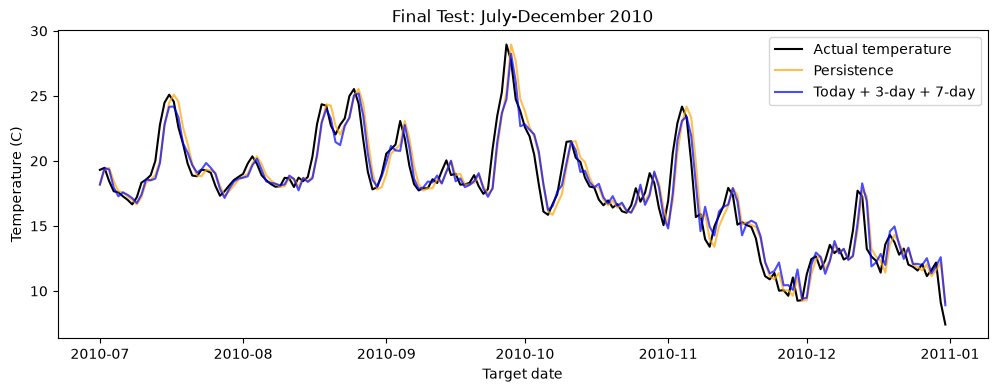

In [82]:
# Compare the real temperatures and both predictions over time.
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(final_test["target_date"], final_test["tomorrow_temp"],
        color="black", label="Actual temperature")
ax.plot(final_test["target_date"], final_test["persistence_pred"],
        color="orange", alpha=0.7, label="Persistence")
ax.plot(final_test["target_date"], final_test["model_pred"],
        color="blue", alpha=0.7, label="Today + 3-day + 7-day")
ax.set_xlabel("Target date")
ax.set_ylabel("Temperature (C)")
ax.set_title("Final Test: July-December 2010")
ax.legend()

## 11. What I learned from version 1

On the July-December 2010 test dates, my temperature model had an MAE of **0.894 C** and an RMSE of **1.185 C**. Persistence had an MAE of **0.998 C** and an RMSE of **1.315 C**. My model lowered MAE by about **10.5%** and RMSE by about **9.9%** compared with persistence.

The improvement I saw during validation also appeared in this test period. Using today's temperature together with the 3-day and 7-day averages worked better than simply copying today's temperature. This does not mean it will work equally well every year.

I first tried maps and line plots to understand the data. Then I tried persistence, linear regression, and different combinations of temperature averages. I kept the dates in order and used the same rows when comparing feature choices. For the final test, I fixed the features before looking at the scores and trained once on the earlier data.

This finishes my temperature-only version. It predicts one day ahead using temperatures already observed each day; it is not a forecast of the whole six months made on June 30.

### What I still want to try

Next, I would like to try pressure or wind in a separate notebook. I have now seen the July-December test results, so that period is no longer a fresh final check for later model choices. I would need another unseen period for that.

I also still need to check whether the grid point represents land near Irvine well. Before using precipitation, I need to understand its units and daily calculation. This project only uses two years of data, so I would like to check more years if they become available.